# MentalDistress — Step 4: Flat Transformer Baselines

One execution trains exactly one configured model: `bert`, `roberta`, `mentalroberta`, or `electra`. MentalRoBERTa authenticates with the Kaggle secret `hf_model_read`; the token is never printed or saved. `RUN_MODE="smoke"` performs two same-seed runs and requires identical predictions and classification metrics, with floating-point logits/losses agreeing within the recorded numerical tolerance. `RUN_MODE="full"` trains on the complete locked training split and evaluates only the locked validation split. The test split is not opened, read, loaded, inferred on, or evaluated.


In [1]:
# CONFIG
import os
from pathlib import Path
# MODEL_REGISTRY = {
#     "bert": "google-bert/bert-base-uncased",
#     "roberta": "FacebookAI/roberta-base",
#     "mentalroberta": "mental/mental-roberta-base",
#     "electra": "google/electra-base-discriminator",
# }
MODEL_KEY = "bert"
RUN_MODE = "full"                 # "full" or "smoke"
DEVICE = "cuda"                   # "cuda" or "cpu"
TRAIN_PATH = Path("/kaggle/input/datasets/sayemahmedshayeed/mentaldistress-locked-dataset/MentalDistress_train_LOCKED.csv")
VALIDATION_PATH = Path("/kaggle/input/datasets/sayemahmedshayeed/mentaldistress-locked-dataset/MentalDistress_validation_LOCKED.csv")
OUTPUT_ROOT = None                 # None -> /kaggle/working/mental_distress_step4
MODEL_SOURCE_OVERRIDE = None       # local model directory, otherwise registry source is used
MODEL_REVISION = None              # optional fixed Hugging Face commit SHA
HF_TOKEN_ENV = "HF_TOKEN"

SEED = 3407
MAX_LENGTH = 512
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
EPOCHS = 8
PATIENCE = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
MAX_GRAD_NORM = 1.0

SMOKE_TRAIN_PER_CLASS = 8
SMOKE_VAL_PER_CLASS = 4
SMOKE_EPOCHS = 1
SMOKE_REPRODUCIBILITY_CHECK = True
REPRO_ATOL = 1e-5
REPRO_RTOL = 1e-6

OVERWRITE_RUN = True
STRICT_DETERMINISM = True

MODEL_REGISTRY = {
    "bert": "google-bert/bert-base-uncased",
    "roberta": "FacebookAI/roberta-base",
    "mentalroberta": "mental/mental-roberta-base",
    "electra": "google/electra-base-discriminator",
}

LABELS = ["Suicidal", "Depressed", "Anxious", "Frustrated", "Others"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

assert MODEL_KEY in MODEL_REGISTRY
assert RUN_MODE in {"full", "smoke"}
assert DEVICE in {"cuda", "cpu"}
assert MAX_LENGTH > 0 and TRAIN_BATCH_SIZE > 0 and EVAL_BATCH_SIZE > 0
assert GRAD_ACCUM_STEPS > 0 and EPOCHS > 0 and PATIENCE > 0


In [2]:
import sys
import json
import math
import random
import hashlib
import shutil
import platform
import subprocess
import zipfile
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import sklearn
    import torch
    import transformers
    transformers.logging.set_verbosity_error()
    import tokenizers
    import huggingface_hub
    import matplotlib.pyplot as plt
    from IPython.display import display
    from sklearn.metrics import (
        accuracy_score,
        classification_report,
        confusion_matrix,
        f1_score,
        matthews_corrcoef,
        precision_score,
        recall_score,
    )
    from torch.utils.data import Dataset, DataLoader
    from transformers import (
        AutoConfig,
        AutoModelForSequenceClassification,
        AutoTokenizer,
        DataCollatorWithPadding,
        get_linear_schedule_with_warmup,
    )
    from huggingface_hub import HfApi
except Exception as exc:
    raise RuntimeError(
        'Required packages are missing. Use a controlled environment with torch, transformers, '
        'tokenizers, huggingface_hub, scikit-learn, pandas, numpy, matplotlib, sentencepiece and safetensors.'
    ) from exc


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    if hasattr(torch.backends, "cuda") and hasattr(torch.backends.cuda, "matmul"):
        torch.backends.cuda.matmul.allow_tf32 = False
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.allow_tf32 = False
    if STRICT_DETERMINISM:
        torch.use_deterministic_algorithms(True, warn_only=False)
    if hasattr(torch, "set_float32_matmul_precision"):
        torch.set_float32_matmul_precision("highest")


seed_everything(SEED)

if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError('DEVICE="cuda" but CUDA is unavailable. Use a GPU runtime or set DEVICE="cpu".')
device = torch.device(DEVICE)

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "tokenizers": tokenizers.__version__,
    "huggingface_hub": huggingface_hub.__version__,
    "cuda_runtime": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
    "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
}
display(pd.DataFrame([environment]))


HF_TOKEN = None
if MODEL_KEY == "mentalroberta":
    try:
        from kaggle_secrets import UserSecretsClient
        from huggingface_hub import login

        user_secrets = UserSecretsClient()
        HF_TOKEN = user_secrets.get_secret("hf_model_read")
        if not HF_TOKEN:
            raise RuntimeError("Kaggle secret 'hf_model_read' is empty.")
        login(token=HF_TOKEN, add_to_git_credential=False)
    except Exception as exc:
        raise RuntimeError(
            "MentalRoBERTa requires Hugging Face authentication. "
            "Add a Kaggle secret named 'hf_model_read' containing a Hugging Face read token."
        ) from exc



,python,platform,numpy,pandas,scikit_learn,torch,transformers,tokenizers,huggingface_hub,cuda_runtime,cudnn,device,gpu,deterministic_algorithms
0,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,2.0.2,2.3.3,1.6.1,2.10.0+cu128,5.0.0,0.22.2,1.11.0,12.8,91002,cuda,Tesla T4,True


In [3]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def sha256_tree(root: Path) -> str:
    h = hashlib.sha256()
    for p in sorted(x for x in root.rglob("*") if x.is_file()):
        h.update(p.relative_to(root).as_posix().encode("utf-8"))
        h.update(sha256_file(p).encode("ascii"))
    return h.hexdigest()


if not TRAIN_PATH.is_file():
    raise FileNotFoundError(f"Training CSV not found: {TRAIN_PATH}")
if not VALIDATION_PATH.is_file():
    raise FileNotFoundError(f"Validation CSV not found: {VALIDATION_PATH}")

frames = {
    "train": pd.read_csv(TRAIN_PATH),
    "validation": pd.read_csv(VALIDATION_PATH),
}

expected_counts = {"train": 6954, "validation": 1490}
expected_classes = {
    "train": {"Others": 1779, "Suicidal": 1492, "Anxious": 1370, "Frustrated": 1292, "Depressed": 1021},
    "validation": {"Others": 381, "Suicidal": 319, "Anxious": 294, "Frustrated": 277, "Depressed": 219},
}
required_columns = {"original_row", "text", "label"}

for name, df in frames.items():
    assert len(df) == expected_counts[name], (name, len(df), expected_counts[name])
    assert required_columns.issubset(df.columns), (name, df.columns.tolist())
    assert df["original_row"].is_unique, f"Duplicate original_row in {name}"
    assert df["text"].notna().all() and df["text"].astype(str).str.strip().ne("").all(), f"Invalid text in {name}"
    assert set(df["label"].unique()) <= set(LABELS), f"Invalid label in {name}"
    got = df["label"].value_counts().to_dict()
    assert got == expected_classes[name], (name, got, expected_classes[name])

train_ids = set(frames["train"]["original_row"])
val_ids = set(frames["validation"]["original_row"])
assert train_ids.isdisjoint(val_ids), "Train/validation row overlap detected."

integrity = {
    "rows": expected_counts,
    "sha256": {
        "train": sha256_file(TRAIN_PATH),
        "validation": sha256_file(VALIDATION_PATH),
    },
    "class_counts": expected_classes,
    "train_validation_disjoint": True,
    "test_accessed": False,
}

display(pd.DataFrame([
    {"split": "train", "rows": len(frames["train"]), "path": str(TRAIN_PATH), "sha256": integrity["sha256"]["train"]},
    {"split": "validation", "rows": len(frames["validation"]), "path": str(VALIDATION_PATH), "sha256": integrity["sha256"]["validation"]},
]))


,split,rows,path,sha256
0,train,6954,/kaggle/input/datasets/sayemahmedshayeed/menta...,1bac0d2f4e0f4d3da940b08a21bd3c6e18b1d958c57cb2...
1,validation,1490,/kaggle/input/datasets/sayemahmedshayeed/menta...,88835cd714b02efbd230536c7de3f455e807051a23a178...


In [4]:
def stratified_smoke_sample(df: pd.DataFrame, per_class: int, seed: int) -> pd.DataFrame:
    parts = []
    for label in LABELS:
        part = df[df["label"] == label]
        n = min(per_class, len(part))
        parts.append(part.sample(n=n, random_state=seed).sort_values("original_row"))
    return pd.concat(parts, ignore_index=True).sort_values("original_row").reset_index(drop=True)


train_df = frames["train"].copy()
val_df = frames["validation"].copy()
if RUN_MODE == "smoke":
    train_df = stratified_smoke_sample(train_df, SMOKE_TRAIN_PER_CLASS, SEED)
    val_df = stratified_smoke_sample(val_df, SMOKE_VAL_PER_CLASS, SEED)

train_df["label_id"] = train_df["label"].map(LABEL2ID).astype(int)
val_df["label_id"] = val_df["label"].map(LABEL2ID).astype(int)

model_source = str(Path(MODEL_SOURCE_OVERRIDE).resolve()) if MODEL_SOURCE_OVERRIDE else MODEL_REGISTRY[MODEL_KEY]
hf_token = os.environ.get(HF_TOKEN_ENV) or None
resolved_revision = MODEL_REVISION

if MODEL_SOURCE_OVERRIDE is None and resolved_revision is None:
    try:
        resolved_revision = HfApi().model_info(model_source, token=hf_token).sha
    except Exception as exc:
        raise RuntimeError(
            "Could not resolve a pinned Hugging Face commit. Enable internet/authentication or set MODEL_REVISION explicitly."
        ) from exc

source_kwargs = {}
if MODEL_SOURCE_OVERRIDE is None:
    source_kwargs["revision"] = resolved_revision
    if hf_token:
        source_kwargs["token"] = hf_token

seed_everything(SEED)
tokenizer = AutoTokenizer.from_pretrained(model_source, use_fast=True, **source_kwargs)
base_config = AutoConfig.from_pretrained(
    model_source,
    num_labels=len(LABELS),
    label2id=LABEL2ID,
    id2label=ID2LABEL,
    **source_kwargs,
)
base_config._attn_implementation = "eager"

resolved_model = {
    "model_key": MODEL_KEY,
        "hf_authenticated": bool(HF_TOKEN is not None),
    "source": model_source,
    "revision": resolved_revision,
    "local_source_sha256": sha256_tree(Path(model_source)) if MODEL_SOURCE_OVERRIDE else None,
    "attention_implementation": getattr(base_config, "_attn_implementation", None),
}

run_signature_payload = {
    "model": resolved_model,
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "grad_accum_steps": GRAD_ACCUM_STEPS,
    "epochs": EPOCHS if RUN_MODE == "full" else SMOKE_EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_ratio": WARMUP_RATIO,
    "max_grad_norm": MAX_GRAD_NORM,
    "run_mode": RUN_MODE,
    "data_sha256": integrity["sha256"],
}
run_signature = hashlib.sha256(json.dumps(run_signature_payload, sort_keys=True).encode("utf-8")).hexdigest()[:12]
run_id = f"{MODEL_KEY}_{RUN_MODE}_seed{SEED}_len{MAX_LENGTH}_{run_signature}"

if OUTPUT_ROOT is None:
    root = Path("/kaggle/working/mental_distress_step4") if Path("/kaggle/working").exists() else Path("/mnt/data/mental_distress_step4")
else:
    root = Path(OUTPUT_ROOT)
run_dir = root / run_id
if run_dir.exists() and OVERWRITE_RUN:
    shutil.rmtree(run_dir)
run_dir.mkdir(parents=True, exist_ok=True)

print(json.dumps({"run_id": run_id, **resolved_model, "train_rows": len(train_df), "validation_rows": len(val_df)}, indent=2))


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{
  "run_id": "bert_full_seed3407_len512_f3fdb7dd6bd0",
  "model_key": "bert",
  "hf_authenticated": false,
  "source": "google-bert/bert-base-uncased",
  "revision": "86b5e0934494bd15c9632b12f734a8a67f723594",
  "local_source_sha256": null,
  "attention_implementation": "eager",
  "train_rows": 6954,
  "validation_rows": 1490
}


In [5]:
class EncodedDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer, max_length: int):
        self.labels = df["label_id"].tolist()
        self.encodings = tokenizer(
            df["text"].astype(str).tolist(),
            truncation=True,
            max_length=max_length,
            padding=False,
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item


collator = DataCollatorWithPadding(tokenizer=tokenizer, padding="longest", return_tensors="pt")
train_dataset = EncodedDataset(train_df, tokenizer, MAX_LENGTH)
val_dataset = EncodedDataset(val_df, tokenizer, MAX_LENGTH)


def make_train_loader(seed: int):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        train_dataset,
        batch_size=TRAIN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        collate_fn=collator,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )


def make_val_loader():
    return DataLoader(
        val_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        collate_fn=collator,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )


def new_model(seed: int):
    seed_everything(seed)
    cfg = AutoConfig.from_pretrained(
        model_source,
        num_labels=len(LABELS),
        label2id=LABEL2ID,
        id2label=ID2LABEL,
        **source_kwargs,
    )
    cfg._attn_implementation = "eager"
    model = AutoModelForSequenceClassification.from_pretrained(model_source, config=cfg, **source_kwargs)
    return model.to(device)


def metric_bundle(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
    }


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_n = 0
    logits_parts, labels_parts = [], []
    with torch.inference_mode():
        for batch in loader:
            labels = batch["labels"].to(device, non_blocking=True)
            inputs = {k: v.to(device, non_blocking=True) for k, v in batch.items() if k != "labels"}
            outputs = model(**inputs, labels=labels)
            bs = labels.size(0)
            total_loss += float(outputs.loss.detach().cpu()) * bs
            total_n += bs
            logits_parts.append(outputs.logits.detach().cpu())
            labels_parts.append(labels.detach().cpu())
    logits = torch.cat(logits_parts, dim=0).numpy()
    y_true = torch.cat(labels_parts, dim=0).numpy()
    probs = torch.softmax(torch.from_numpy(logits), dim=1).numpy()
    y_pred = probs.argmax(axis=1)
    metrics = metric_bundle(y_true, y_pred)
    metrics["loss"] = total_loss / total_n
    return {"metrics": metrics, "logits": logits, "probs": probs, "y_true": y_true, "y_pred": y_pred}


In [6]:
def save_best_checkpoint(model, checkpoint_dir: Path, meta: dict):
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(checkpoint_dir, safe_serialization=True)
    tokenizer.save_pretrained(checkpoint_dir)
    with (checkpoint_dir / "checkpoint_meta.json").open("w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, sort_keys=True)


def train_once(target_dir: Path, seed: int, epochs: int):
    if target_dir.exists():
        shutil.rmtree(target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

    model = new_model(seed)
    train_loader = make_train_loader(seed)
    val_loader = make_val_loader()

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    optimizer_steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
    total_optimizer_steps = optimizer_steps_per_epoch * epochs
    warmup_steps = int(round(total_optimizer_steps * WARMUP_RATIO))
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_optimizer_steps,
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = None
    no_improve = 0
    history = []
    checkpoint_dir = target_dir / "best_model"

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        train_loss_sum = 0.0
        train_n = 0
        train_preds, train_labels = [], []

        for step, batch in enumerate(train_loader):
            labels = batch["labels"].to(device, non_blocking=True)
            inputs = {k: v.to(device, non_blocking=True) for k, v in batch.items() if k != "labels"}
            outputs = model(**inputs, labels=labels)
            raw_loss = outputs.loss
            (raw_loss / GRAD_ACCUM_STEPS).backward()

            bs = labels.size(0)
            train_loss_sum += float(raw_loss.detach().cpu()) * bs
            train_n += bs
            train_preds.extend(outputs.logits.detach().argmax(dim=1).cpu().tolist())
            train_labels.extend(labels.detach().cpu().tolist())

            do_step = ((step + 1) % GRAD_ACCUM_STEPS == 0) or (step + 1 == len(train_loader))
            if do_step:
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

        val_out = evaluate(model, val_loader)
        train_metrics = metric_bundle(np.array(train_labels), np.array(train_preds))
        row = {
            "epoch": epoch,
            "train_loss": train_loss_sum / train_n,
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_out["metrics"]["loss"],
            "val_macro_f1": val_out["metrics"]["macro_f1"],
            "val_accuracy": val_out["metrics"]["accuracy"],
            "learning_rate": float(scheduler.get_last_lr()[0]),
        }
        history.append(row)
        print(json.dumps(row, sort_keys=True))

        improved = (
            row["val_macro_f1"] > best_f1 + 1e-12
            or (abs(row["val_macro_f1"] - best_f1) <= 1e-12 and row["val_loss"] < best_loss - 1e-12)
        )
        if improved:
            best_f1 = row["val_macro_f1"]
            best_loss = row["val_loss"]
            best_epoch = epoch
            no_improve = 0
            save_best_checkpoint(
                model,
                checkpoint_dir,
                {
                    "best_epoch": best_epoch,
                    "validation_macro_f1": best_f1,
                    "validation_loss": best_loss,
                    "seed": seed,
                    "run_id": run_id,
                    "test_accessed": False,
                },
            )
        else:
            no_improve += 1
            if RUN_MODE == "full" and no_improve >= PATIENCE:
                break

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

    reload_model = AutoModelForSequenceClassification.from_pretrained(checkpoint_dir).to(device)
    reloaded = evaluate(reload_model, make_val_loader())
    del reload_model
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "history": history,
        "best_epoch": best_epoch,
        "checkpoint_dir": checkpoint_dir,
        "validation": reloaded,
    }


epochs_to_run = EPOCHS if RUN_MODE == "full" else SMOKE_EPOCHS
primary_dir = run_dir / "primary"
primary = train_once(primary_dir, SEED, epochs_to_run)

reproducibility_check = {"performed": False, "passed": None}
if RUN_MODE == "smoke" and SMOKE_REPRODUCIBILITY_CHECK:
    second_dir = run_dir / "repro_second"
    second = train_once(second_dir, SEED, epochs_to_run)

    primary_logits = primary["validation"]["logits"]
    second_logits = second["validation"]["logits"]

    same_predictions = np.array_equal(
        primary["validation"]["y_pred"],
        second["validation"]["y_pred"],
    )

    metric_keys = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "mcc"]
    same_discrete_metrics = all(
        primary["validation"]["metrics"][key] == second["validation"]["metrics"][key]
        for key in metric_keys
    )

    logits_close = np.allclose(
        primary_logits,
        second_logits,
        rtol=REPRO_RTOL,
        atol=REPRO_ATOL,
        equal_nan=True,
    )
    logits_max_abs_diff = float(np.max(np.abs(primary_logits - second_logits)))

    primary_history = pd.DataFrame(primary["history"])
    second_history = pd.DataFrame(second["history"])
    same_history_shape = primary_history.shape == second_history.shape
    same_history_columns = primary_history.columns.tolist() == second_history.columns.tolist()

    history_close = bool(same_history_shape and same_history_columns)
    history_max_abs_diff = 0.0
    if history_close:
        for column in primary_history.columns:
            a = primary_history[column].to_numpy()
            b = second_history[column].to_numpy()

            if np.issubdtype(a.dtype, np.number):
                a_float = a.astype(float)
                b_float = b.astype(float)
                diff = np.abs(a_float - b_float)
                if diff.size:
                    history_max_abs_diff = max(history_max_abs_diff, float(np.nanmax(diff)))
                if not np.allclose(
                    a_float,
                    b_float,
                    rtol=REPRO_RTOL,
                    atol=REPRO_ATOL,
                    equal_nan=True,
                ):
                    history_close = False
                    break
            elif not np.array_equal(a, b):
                history_close = False
                break

    validation_loss_close = bool(
        np.isclose(
            primary["validation"]["metrics"]["loss"],
            second["validation"]["metrics"]["loss"],
            rtol=REPRO_RTOL,
            atol=REPRO_ATOL,
        )
    )

    reproducibility_check = {
        "performed": True,
        "same_predictions": bool(same_predictions),
        "same_discrete_metrics": bool(same_discrete_metrics),
        "logits_close": bool(logits_close),
        "logits_max_abs_diff": logits_max_abs_diff,
        "history_close": bool(history_close),
        "history_max_abs_diff": history_max_abs_diff,
        "validation_loss_close": validation_loss_close,
        "rtol": REPRO_RTOL,
        "atol": REPRO_ATOL,
        "passed": bool(
            same_predictions
            and same_discrete_metrics
            and logits_close
            and history_close
            and validation_loss_close
        ),
    }

    shutil.rmtree(second_dir)
    assert reproducibility_check["passed"], reproducibility_check

print(json.dumps({"best_epoch": primary["best_epoch"], "validation": primary["validation"]["metrics"], "reproducibility": reproducibility_check}, indent=2))


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{"epoch": 1, "learning_rate": 1.9439490445859873e-05, "train_loss": 1.1681913180410142, "train_macro_f1": 0.49458298721373223, "val_accuracy": 0.761744966442953, "val_loss": 0.645694731785947, "val_macro_f1": 0.7488302303359822}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 2, "learning_rate": 1.666242038216561e-05, "train_loss": 0.5043290413193982, "train_macro_f1": 0.8155556184883608, "val_accuracy": 0.8208053691275168, "val_loss": 0.5192128596689877, "val_macro_f1": 0.818153151570996}


...

{"epoch": 3, "learning_rate": 1.3885350318471338e-05, "train_loss": 0.290504577668501, "train_macro_f1": 0.9039536437196188, "val_accuracy": 0.838255033557047, "val_loss": 0.48506023185765185, "val_macro_f1": 0.8341412955866716}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "train_loss": 0.1616999599284436, "train_macro_f1": 0.952004355831156, "val_accuracy": 0.8268456375838926, "val_loss": 0.5691827807750478, "val_macro_f1": 0.822618489470045}
{"epoch": 5, "learning_rate": 8.331210191082804e-06, "train_loss": 0.08615986925681321, "train_macro_f1": 0.9764824457716916, "val_accuracy": 0.8281879194630872, "val_loss": 0.653567811986744, "val_macro_f1": 0.8227192369657239}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "train_loss": 0.042954584760556566, "train_macro_f1": 0.9883795376737148, "val_accuracy": 0.8355704697986577, "val_loss": 0.723195504795935, "val_macro_f1": 0.8307328049281353}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "best_epoch": 3,
  "validation": {
    "accuracy": 0.838255033557047,
    "macro_precision": 0.838290450145735,
    "macro_recall": 0.831164349929538,
    "macro_f1": 0.8341412955866716,
    "weighted_f1": 0.8379282249818834,
    "mcc": 0.7960971802849891,
    "loss": 0.4850602446986525
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


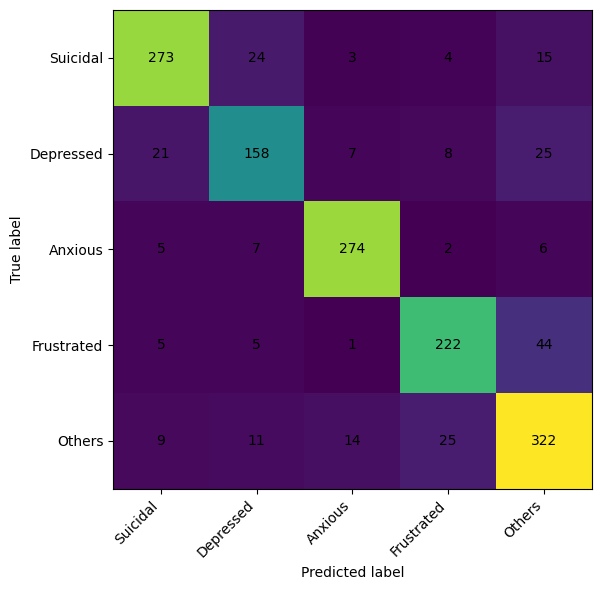

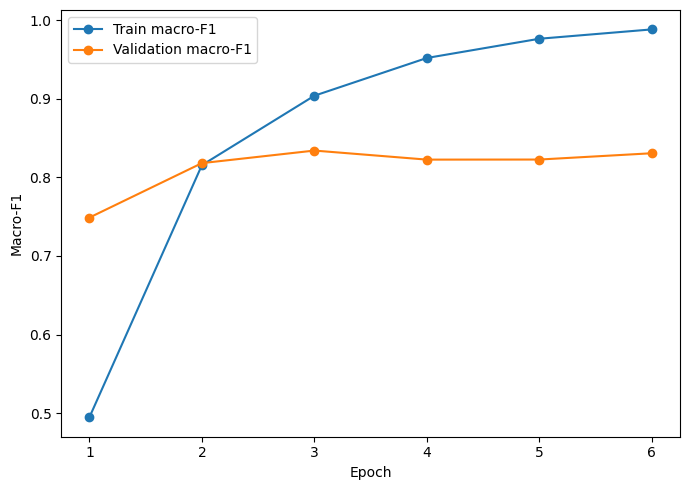

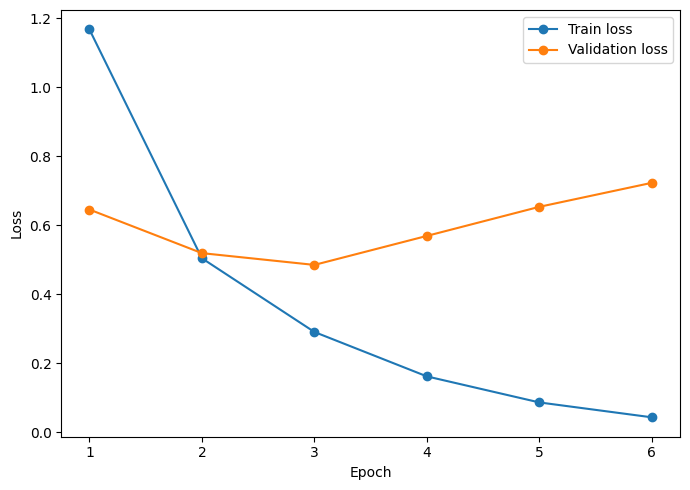

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,0.838255,0.83829,0.831164,0.834141,0.837928,0.796097,0.48506


,precision,recall,f1-score,support
Suicidal,0.872204,0.855799,0.863924,319.000000
Depressed,0.770732,0.721461,0.745283,219.000000
Anxious,0.916388,0.931973,0.924115,294.000000
Frustrated,0.850575,0.801444,0.825279,277.000000
Others,0.781553,0.845144,0.812106,381.000000
accuracy,0.838255,0.838255,0.838255,0.838255
macro avg,0.838290,0.831164,0.834141,1490.000000
weighted avg,0.838807,0.838255,0.837928,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,273,24,3,4,15
Depressed,21,158,7,8,25
Anxious,5,7,274,2,6
Frustrated,5,5,1,222,44
Others,9,11,14,25,322


In [7]:
artifacts_dir = run_dir / "artifacts"
models_dir = run_dir / "models"
artifacts_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

best_model_source = primary["checkpoint_dir"]
final_model_dir = models_dir / "best_model"
if final_model_dir.exists():
    shutil.rmtree(final_model_dir)
shutil.copytree(best_model_source, final_model_dir)
if primary_dir.exists():
    shutil.rmtree(primary_dir)

val_out = primary["validation"]
y_true = val_out["y_true"]
y_pred = val_out["y_pred"]
probs = val_out["probs"]
logits = val_out["logits"]
metrics = val_out["metrics"]

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(LABELS))),
    target_names=LABELS,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report_dict).T
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(LABELS))))
cm_df = pd.DataFrame(cm, index=LABELS, columns=LABELS)

pred_df = pd.DataFrame({
    "original_row": val_df["original_row"].to_numpy(),
    "true_label": val_df["label"].to_numpy(),
    "true_id": y_true,
    "predicted_id": y_pred,
    "predicted_label": [ID2LABEL[int(i)] for i in y_pred],
})
for i, label in enumerate(LABELS):
    pred_df[f"logit_{label}"] = logits[:, i]
    pred_df[f"prob_{label}"] = probs[:, i]

history_df = pd.DataFrame(primary["history"])

run_config = {
    **run_signature_payload,
    "run_id": run_id,
    "label2id": LABEL2ID,
    "id2label": ID2LABEL,
    "resolved_model": resolved_model,
    "train_rows_used": len(train_df),
    "validation_rows_used": len(val_df),
    "test_accessed": False,
}

with (artifacts_dir / "config.json").open("w", encoding="utf-8") as f:
    json.dump(run_config, f, indent=2, sort_keys=True)
with (artifacts_dir / "environment.json").open("w", encoding="utf-8") as f:
    json.dump(environment, f, indent=2, sort_keys=True)
with (artifacts_dir / "dataset_integrity.json").open("w", encoding="utf-8") as f:
    json.dump(integrity, f, indent=2, sort_keys=True)
with (artifacts_dir / "validation_metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, sort_keys=True)
with (artifacts_dir / "reproducibility_check.json").open("w", encoding="utf-8") as f:
    json.dump(reproducibility_check, f, indent=2, sort_keys=True)

history_df.to_csv(artifacts_dir / "training_history.csv", index=False, float_format="%.17g")
pred_df.to_csv(artifacts_dir / "validation_predictions.csv", index=False, float_format="%.17g")
report_df.to_csv(artifacts_dir / "validation_classification_report.csv", float_format="%.17g")
cm_df.to_csv(artifacts_dir / "validation_confusion_matrix.csv")

try:
    freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
except Exception:
    freeze = ""
(artifacts_dir / "pip_freeze.txt").write_text(freeze, encoding="utf-8")

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111)
im = ax.imshow(cm)
ax.set_xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.tight_layout()
fig.savefig(artifacts_dir / "validation_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
ax.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Train macro-F1")
ax.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation macro-F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.legend()
fig.tight_layout()
fig.savefig(artifacts_dir / "macro_f1_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
ax.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
fig.tight_layout()
fig.savefig(artifacts_dir / "loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

display(pd.DataFrame([metrics]))
display(report_df)
display(cm_df)


In [8]:
def write_hash_manifest(root: Path, output_file: Path):
    rows = []
    for p in sorted(x for x in root.rglob("*") if x.is_file() and x != output_file):
        rows.append({"path": p.relative_to(root).as_posix(), "sha256": sha256_file(p), "bytes": p.stat().st_size})
    pd.DataFrame(rows).to_csv(output_file, index=False)


def deterministic_zip(source_dir: Path, zip_path: Path, prefix: str):
    fixed_time = (2020, 1, 1, 0, 0, 0)
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zf:
        for p in sorted(x for x in source_dir.rglob("*") if x.is_file()):
            rel = Path(prefix) / p.relative_to(source_dir)
            info = zipfile.ZipInfo(rel.as_posix(), fixed_time)
            info.compress_type = zipfile.ZIP_DEFLATED
            info.external_attr = 0o644 << 16
            zf.writestr(info, p.read_bytes())


write_hash_manifest(models_dir, models_dir / "sha256_manifest.csv")
write_hash_manifest(artifacts_dir, artifacts_dir / "sha256_manifest.csv")

reloaded_model = AutoModelForSequenceClassification.from_pretrained(final_model_dir).to(device)
reloaded_out = evaluate(reloaded_model, make_val_loader())
assert np.array_equal(y_pred, reloaded_out["y_pred"]), "Saved model predictions differ after reload."
reload_logits_max_abs_diff = float(np.max(np.abs(logits - reloaded_out["logits"])))
assert np.allclose(
    logits,
    reloaded_out["logits"],
    rtol=REPRO_RTOL,
    atol=REPRO_ATOL,
    equal_nan=True,
), f"Saved model logits differ beyond tolerance; max_abs_diff={reload_logits_max_abs_diff}"
del reloaded_model
if device.type == "cuda":
    torch.cuda.empty_cache()

metrics_recomputed = metric_bundle(pred_df["true_id"].to_numpy(), pred_df["predicted_id"].to_numpy())
for key in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "mcc"]:
    assert abs(metrics_recomputed[key] - metrics[key]) <= 1e-15, (key, metrics_recomputed[key], metrics[key])

model_zip = run_dir.parent / f"{run_id}_MODELS.zip"
artifact_zip = run_dir.parent / f"{run_id}_ARTIFACTS.zip"
for p in [model_zip, artifact_zip]:
    if p.exists():
        p.unlink()
deterministic_zip(models_dir, model_zip, "models")
deterministic_zip(artifacts_dir, artifact_zip, "artifacts")

final_status = {
    "run_id": run_id,
    "model_zip": str(model_zip),
    "model_zip_sha256": sha256_file(model_zip),
    "artifact_zip": str(artifact_zip),
    "artifact_zip_sha256": sha256_file(artifact_zip),
    "validation_macro_f1": metrics["macro_f1"],
    "validation_accuracy": metrics["accuracy"],
    "best_epoch": primary["best_epoch"],
    "saved_model_predictions_exact_after_reload": True,
    "saved_model_logits_within_tolerance_after_reload": True,
    "saved_model_reload_logits_max_abs_diff": reload_logits_max_abs_diff,
    "test_accessed": False,
    "status": "PASS",
}
print(json.dumps(final_status, indent=2))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "run_id": "bert_full_seed3407_len512_f3fdb7dd6bd0",
  "model_zip": "/kaggle/working/mental_distress_step4/bert_full_seed3407_len512_f3fdb7dd6bd0_MODELS.zip",
  "model_zip_sha256": "00137d9058e66b9934860ae0843fc1d0cfa7d4306e334a36e42d43bc9db35205",
  "artifact_zip": "/kaggle/working/mental_distress_step4/bert_full_seed3407_len512_f3fdb7dd6bd0_ARTIFACTS.zip",
  "artifact_zip_sha256": "ee483f9c0fa1198680111574f3c885bee69f506cee406dd86c22fe270bd491c0",
  "validation_macro_f1": 0.8341412955866716,
  "validation_accuracy": 0.838255033557047,
  "best_epoch": 3,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}
